# CR gate: scqubits + QuTiP

Putting together a couple of things I was searching for and couldn't find in one place -
going from target transmon frequencies down to a lab-frame CR pulse sim. Posting this
as a starting point in case it's useful to someone else too.

In [ ]:
!pip install scqubits qutip -q
import numpy as np
import matplotlib.pyplot as plt
import scqubits as scq
from qutip import Qobj, basis, tensor, qeye, mesolve, expect
from scipy.optimize import fsolve

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 34.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.5/28.5 MB 56.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 82.2/82.2 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 120.0/120.0 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 150.3/150.3 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.8/56.8 kB 3.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.0.0 requires dill<0.3.9,>=0.3.0, but you have dill 0.4.1 which is incompatible.
datasets 4.0.0 requires multiprocess<0.70.17, but you have multiprocess 0.70.19 which is incompatible.


solving for `EJ, EC` given a target `f01, anharmonicity` (scqubits wants EJ/EC, chip design wants frequencies)

In [ ]:
def transmon_freq_anharm(EJ, EC, ncut=30):
    tm = scq.Transmon(EJ=EJ, EC=EC, ng=0.0, ncut=ncut, truncated_dim=3)
    return tm.E01(), tm.anharmonicity()

def solve_EJ_EC(f01_target, alpha_target, ncut=30):
    EC0 = abs(alpha_target)                        # standard transmon asymptotics as a
    EJ0 = (f01_target + EC0)**2 / (8*EC0)           # starting guess for fsolve
    def resid(x):
        EJ, EC = x
        f, a = transmon_freq_anharm(EJ, EC, ncut)   # exact diagonalized values
        return [f - f01_target, a - alpha_target]
    EJ, EC = fsolve(resid, [EJ0, EC0])
    return EJ, EC

design point for control + target qubit

In [ ]:
# design targets carried over from the qutip notebook's design point
f01_control, alpha_control = 5.7, -0.298   # GHz
f01_target_q, alpha_target_q = 4.3, -0.30 # GHz ("target" as in target qubit, not target value)

EJ1, EC1 = solve_EJ_EC(f01_control, alpha_control)
EJ2, EC2 = solve_EJ_EC(f01_target_q, alpha_target_q)

print(f'Control qubit:  EJ = {EJ1:.3f} GHz, EC = {EC1:.4f} GHz  (EJ/EC = {EJ1/EC1:.1f})')
print(f'Target  qubit:  EJ = {EJ2:.3f} GHz, EC = {EC2:.4f} GHz  (EJ/EC = {EJ2/EC2:.1f})')
print('Verification (should match targets exactly):')
print(' control:', transmon_freq_anharm(EJ1, EC1))
print(' target: ', transmon_freq_anharm(EJ2, EC2))

Control qubit:  EJ = 16.886 GHz, EC = 0.2645 GHz  (EJ/EC = 63.8)
Target  qubit:  EJ = 10.245 GHz, EC = 0.2550 GHz  (EJ/EC = 40.2)
Verification (should match targets exactly):
 control: (np.float64(5.700000000000063), np.float64(-0.2979999999999592))
 target:  (np.float64(4.2999999999999865), np.float64(-0.30000000000013305))


quick look at the wavefunctions, just to sanity check nothing looks broken

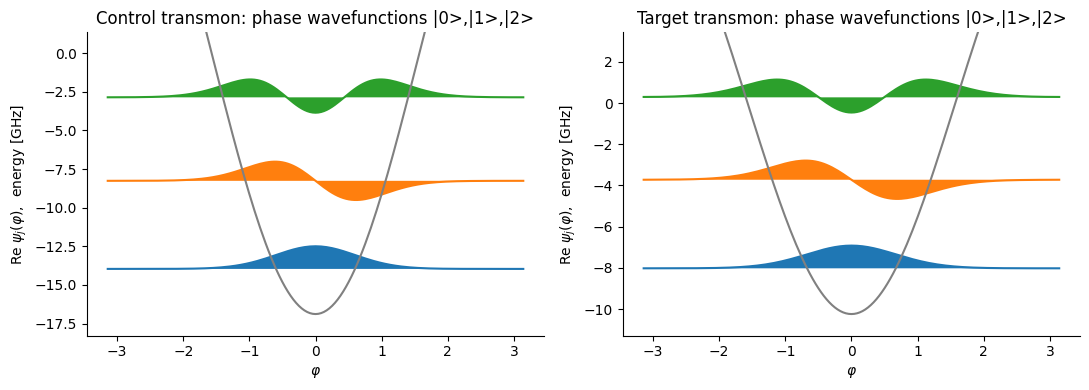

In [ ]:
tm_control = scq.Transmon(EJ=EJ1, EC=EC1, ng=0.0, ncut=30, truncated_dim=3, id_str='control')
tm_target  = scq.Transmon(EJ=EJ2, EC=EC2, ng=0.0, ncut=30, truncated_dim=3, id_str='target')

fig, axes = plt.subplots(1, 2, figsize=(11,4))
tm_control.plot_wavefunction(which=[0,1,2], mode='real', fig_ax=(fig, axes[0]))
axes[0].set_title('Control transmon: phase wavefunctions |0>,|1>,|2>')
tm_target.plot_wavefunction(which=[0,1,2], mode='real', fig_ax=(fig, axes[1]))
axes[1].set_title('Target transmon: phase wavefunctions |0>,|1>,|2>')
plt.tight_layout(); plt.show()

now couple them and check bare vs dressed levels - this is where the static ZZ shows up

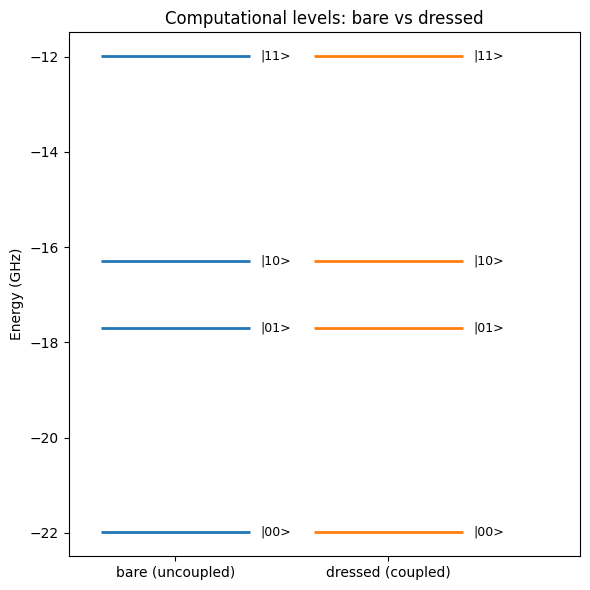

ZZ (bare, should be ~0):  -0.000000 MHz
ZZ (dressed/coupled):     -0.055628 MHz


In [ ]:
def build_hilbertspace(EJ1, EC1, EJ2, EC2, g):
    tm1 = scq.Transmon(EJ=EJ1, EC=EC1, ng=0.0, ncut=30, truncated_dim=3, id_str='control')
    tm2 = scq.Transmon(EJ=EJ2, EC=EC2, ng=0.0, ncut=30, truncated_dim=3, id_str='target')
    hs = scq.HilbertSpace([tm1, tm2])
    hs.add_interaction(g=g, op1=tm1.n_operator, op2=tm2.n_operator, add_hc=False)  # charge-charge coupling
    hs.generate_lookup()
    return hs, tm1, tm2

g_design = 0.008  # GHz, starting point (same as qutip notebook); revisited by the sweep below
hs, tm1, tm2 = build_hilbertspace(EJ1, EC1, EJ2, EC2, g_design)

Hbare = hs.bare_hamiltonian()          # exactly diagonal in the product basis
Hcoupled = hs.hamiltonian()            # bare + interaction

E_bare = np.sort(Hbare.full().real.diagonal())
E_coupled = hs.eigenvals(evals_count=9)

# bare product-basis labels: diagonal order is row-major (i,j) for truncated_dim=3 each
bare_diag = Hbare.full().real.diagonal()
order = np.argsort(bare_diag)
labels_bare = [f'|{k//3}{k%3}>' for k in order]

keep = ['|00>', '|01>', '|10>', '|11>']
E_bare_sorted = bare_diag[order]

fig, ax = plt.subplots(figsize=(6,6))
for e, l in zip(E_bare_sorted, labels_bare):
    if l in keep:
        ax.hlines(e, -0.35, 0.35, color='C0', lw=2)
        ax.text(0.4, e, l, va='center', fontsize=9)
# label dressed levels via dressed_index for the four computational states directly
comp_states = {'|00>': (0,0), '|01>': (0,1), '|10>': (1,0), '|11>': (1,1)}
for lbl, (i,j) in comp_states.items():
    idx = hs.dressed_index((i,j))
    e = E_coupled[idx]
    ax.hlines(e, 1-0.35, 1+0.35, color='C1', lw=2)
    ax.text(1.4, e, lbl, va='center', fontsize=9)

ax.set_xticks([0,1]); ax.set_xticklabels(['bare (uncoupled)', 'dressed (coupled)'])
ax.set_ylabel('Energy (GHz)')
ax.set_title('Computational levels: bare vs dressed')
ax.set_xlim(-0.5, 1.9)
plt.tight_layout(); plt.show()

E00_b, E01_b, E10_b, E11_b = [dict(zip(labels_bare, E_bare_sorted))[l] for l in keep]
zz_bare = (E11_b + E00_b - E01_b - E10_b)*1e3
E00_d = E_coupled[hs.dressed_index((0,0))]
E01_d = E_coupled[hs.dressed_index((0,1))]
E10_d = E_coupled[hs.dressed_index((1,0))]
E11_d = E_coupled[hs.dressed_index((1,1))]
zz_dressed = (E11_d + E00_d - E01_d - E10_d)*1e3
print(f'ZZ (bare, should be ~0):  {zz_bare:.6f} MHz')
print(f'ZZ (dressed/coupled):     {zz_dressed:.6f} MHz')

### CR gate, full lab-frame sim

No rotating frame, no RWA - build the Hamiltonian in scqubits, convert to rad/ns, and let
qutip's `sesolve` do the exact time evolution under a Gaussian flat-top drive on the
control qubit. Good cross-check against a rotating-frame design.

f1 : 5.049851094254854, a1 : -0.32997772884978893
f2 : 4.735239896144025, a2 : -0.2999727170051578
f_dressed_1 = 5.0502415203622935
f_dressed_2 = 4.734825329496051


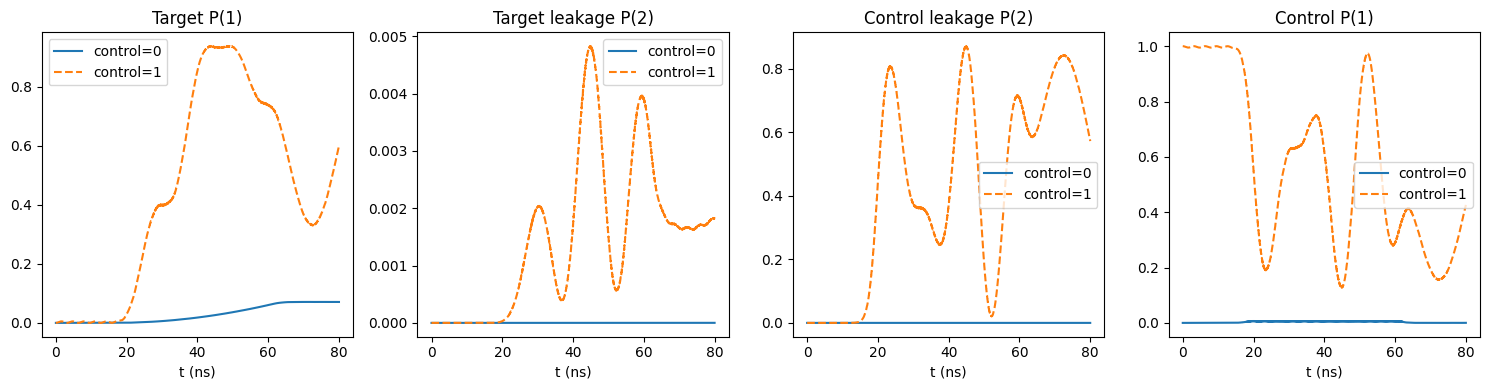

In [ ]:
"""
CR gate: full lab-frame time evolution (no rotating frame, no RWA).
Hamiltonian built directly in scqubits, converted to angular-frequency
units, and evolved exactly with qutip.sesolve under a Gaussian-flat-top
carrier drive on the CONTROL qubit's charge operator.
"""
import numpy as np
import qutip as qt
import scqubits as scq
import matplotlib.pyplot as plt

# ---------------------------------------------------------------
# 1. Parameters -- using the Section-5 optimized design point
# ---------------------------------------------------------------
EJ1, EC1 = 12.613, 0.2838      # control transmon
EJ2, EC2 = 12.101, 0.2593      # target transmon (optimum from sweep)
g_coup   = 0.01          # GHz  (2.53 MHz coupling)
trunc    = 3                   # keep |0>,|1>,|2> per transmon

f1,a1 = transmon_freq_anharm(EJ1, EC1)
f2,a2 = transmon_freq_anharm(EJ2, EC2)


# If you want to try different frequencies
# f1, a1 = 5.7 , -0.3
# f2, a2 = 5.3, -0.3

# EJ1, EC1 = solve_EJ_EC(f1, a1)   # overwrites the values above with the refit ones - this is the actual design point used below
# EJ2, EC2 = solve_EJ_EC(f2, a2)

print(f"f1 : {f1}, a1 : {a1}")
print(f"f2 : {f2}, a2 : {a2}")

#

tm_control = scq.Transmon(EJ=EJ1, EC=EC1, ng=0.0, ncut=30,
                           truncated_dim=trunc, id_str='control')
tm_target  = scq.Transmon(EJ=EJ2, EC=EC2, ng=0.0, ncut=30,
                           truncated_dim=trunc, id_str='target')

hs = scq.HilbertSpace([tm_control, tm_target])
hs.add_interaction(g=g_coup, op1=tm_control.n_operator,
                    op2=tm_target.n_operator, add_hc=False)
hs.generate_lookup()


# static Hamiltonian (bare + capacitive coupling), scqubits gives GHz (=f, not omega)
H0_GHz = hs.hamiltonian()
H0 = 2 * np.pi * H0_GHz          # -> rad/ns, consistent with qutip's exp(-i H t)

# charge operator of the CONTROL qubit, identity-wrapped into the joint space
n1_full = scq.identity_wrap(tm_control.n_operator, tm_control, [tm_control, tm_target])
n2_full = scq.identity_wrap(tm_target.n_operator, tm_target, [tm_control, tm_target])
# n2_full isn't used in H_t below (CR only needs the control-qubit drive), but it's here
# if you want to try driving the target qubit too - single qubit dynamics on either qubit,
# or a two-tone drive on both, can be handy to poke at while tuning parameters

# ---------------------------------------------------------------
# 2. Drive frequency = dressed target 0->1 transition
# ---------------------------------------------------------------
evals = hs.eigenvals(evals_count=9)
E00 = evals[hs.dressed_index((0, 0))]
E01 = evals[hs.dressed_index((1, 0))]
f_d1 = E01 - E00                  # GHz
omega_d1 = 2 * np.pi * f_d1        # rad/ns

E10 = evals[hs.dressed_index((0, 1))]
f_d2 = E10 - E00
print(f"f_dressed_1 = {f_d1}")
print(f"f_dressed_2 = {f_d2}")          # GHz
omega_d2 = 2 * np.pi * f_d2        # rad/ns


# ---------------------------------------------------------------
# 3. Gaussian flat-top envelope x cosine carrier (amplitude modulation)
# ---------------------------------------------------------------
t_rise, t_flat, sigma = 20,40, 3.0     # ns
t_total = 2*t_rise + t_flat

# peak amplitude in GHz (frequency units); ~2x your old RWA Omega_d_cap
# to recover a comparable rotation rate once RWA is removed
amp_GHz = 0.046

def envelope(t):
    if t < t_rise:
        return -amp_GHz * np.exp(-0.5 * ((t - t_rise) / sigma) ** 2)
    elif t < t_rise + t_flat:
        return -amp_GHz
    elif t <= t_total:
        return -amp_GHz * np.exp(-0.5 * ((t - (t_rise + t_flat)) / sigma) ** 2)
    return 0.0

def drive_coeff_1(t, args):
    return 2 * np.pi * envelope(t) * np.cos(omega_d2 * t)   # rad/ns, lab frame, no RWA
    # this is the drive actually used in H_t - drives the control qubit's charge operator (n1_full)

def drive_coeff_2(t, args):
    return 2 * np.pi * envelope(t) * np.cos(omega_d2 * t)   # rad/ns, lab frame, no RWA
    # not wired into H_t by default - pairs with n2_full if you want to drive the target
    # qubit as well, e.g. add ", [n2_full, drive_coeff_2]" to the H_t list below

H_t = [H0, [n1_full, drive_coeff_1]]
# H_t = [H0, [n1_full, drive_coeff_1], [n2_full, drive_coeff_2]]   # drive both qubits instead



# ---------------------------------------------------------------
# 4. Time evolution -- fine grid, no RWA means fast oscillations must be resolved
# ---------------------------------------------------------------
def basis2(i, j):
    return qt.tensor(qt.basis(trunc, i), qt.basis(trunc, j))

psi0_c0 = basis2(0, 0)   # control = 0
psi0_c1 = basis2(1, 0)   # control = 1

P_target1  = qt.tensor(qt.qeye(trunc), qt.basis(trunc, 1) * qt.basis(trunc, 1).dag())
P_target2  = qt.tensor(qt.qeye(trunc), qt.basis(trunc, 2) * qt.basis(trunc, 2).dag())
P_control1 = qt.tensor(qt.basis(trunc, 1) * qt.basis(trunc, 1).dag(), qt.qeye(trunc))
P_control2 = qt.tensor(qt.basis(trunc, 2) * qt.basis(trunc, 2).dag(), qt.qeye(trunc))

tlist = np.linspace(0, t_total, 20000)   # dt ~ 0.002 ns to resolve ~5 GHz oscillations

opts = {"nsteps": 200000, "atol": 1e-10, "rtol": 1e-8}
res_c0 = qt.sesolve(H_t, psi0_c0, tlist, e_ops=[P_target1, P_target2, P_control2, P_control1], options=opts)
res_c1 = qt.sesolve(H_t, psi0_c1, tlist, e_ops=[P_target1, P_target2, P_control2, P_control1], options=opts)

# ---------------------------------------------------------------
# 5. Plot
# ---------------------------------------------------------------
fig, axes = plt.subplots(1, 4, figsize=(15, 4))

axes[0].plot(tlist, res_c0.expect[0], label='control=0')
axes[0].plot(tlist, res_c1.expect[0], '--', label='control=1')
axes[0].set_title('Target P(1)'); axes[0].set_xlabel('t (ns)'); axes[0].legend()

axes[1].plot(tlist, res_c0.expect[1], label='control=0')
axes[1].plot(tlist, res_c1.expect[1], '--', label='control=1')
axes[1].set_title('Target leakage P(2)'); axes[1].set_xlabel('t (ns)'); axes[1].legend()

axes[2].plot(tlist, res_c0.expect[2], label='control=0')
axes[2].plot(tlist, res_c1.expect[2], '--', label='control=1')
axes[2].set_title('Control leakage P(2)'); axes[2].set_xlabel('t (ns)'); axes[2].legend()

axes[3].plot(tlist, res_c0.expect[3], label='control=0')
axes[3].plot(tlist, res_c1.expect[3], '--', label='control=1')
axes[3].set_title('Control P(1)'); axes[3].set_xlabel('t (ns)'); axes[3].legend()

plt.tight_layout()
# plt.savefig('/mnt/user-data/outputs/cr_labframe_result.png', dpi=150)
plt.show()

For these frequencies values we see the leakage to Control qubit state 2, because that is at $f_1 - a_1 ≈ f_2$